In [7]:
import json

# Load selected-samples-data 
with open('/home/lwu/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/sbatch_files/results/allSelected_uniqueSampleIdx_list_LW20230121.json', 'r') as f:
    samples = json.load(f)
print("Total # Biosamples:", len(samples))

# Get unselected samples 
first_100_sample_idxs = list(range(310412,310512 ))
unselected_samples_idxs = [x for x in first_100_sample_idxs if x not in samples]
print("From the first 100 ARCHS4 samples, total samples not selected:", len(unselected_samples_idxs))



Total # Biosamples: 192601
From the first 100 ARCHS4 samples, total samples not selected: 100


In [8]:
# See unselected samples names 
##############################
import h5py
import re
from collections import Counter

# Open ARCHS4 v2.1 Data
infile = "/home/ajoshi/archs4/data/archs4_gene_human_v2.1.h5"
with h5py.File(infile, 'r') as hdf5_file:
    meta = hdf5_file['meta']
    sample_names = meta['samples']['source_name_ch1'][:]

# Decode source names using list comprehension
sample_names_decoded = [x.decode('UTF-8') for x in sample_names]

# Clean source names using regular expressions
sample_names_cleaned = [re.sub(r'[-/\'\\ _]', '', x) for x in sample_names_decoded]

# ^^^^^
unselected_sample_names = [sample_names_cleaned[i] for i in unselected_samples_idxs]

# Count occurrences of each sample name
sample_name_counts = Counter(unselected_sample_names)

# Print the counts
#print(sample_name_counts)
print("# Unique Unselected Sample Names:", len(sample_name_counts))

# Unique Unselected Sample Names: 16


{'Bronchialepithelialcells': 18, 'Subject9': 8, 'Subject2': 7, 'Subject11': 7, 'Subject12': 7, 'Subject3': 6, 'Subject4': 6, 'Subject7': 6, 'Subject13': 6, 'Subject1': 5, 'Subject8': 5, 'Subject10': 5, 'Subject14': 5, 'Subject6': 4, 'Subject15': 3, 'Subject5': 2}

# Plot Read Counts

In [9]:
import pickle

pickle_in = open("/home/lwu/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/data_results/archs4_cols_allSamples_readCountSum.pkl", 'rb')
allSample_readCounts = pickle.load(pickle_in)
pickle_in.close()

unselected_sample_readCounts = [allSample_readCounts[i] for i in unselected_samples_idxs]


array([ 99379321,  85980162, 107921128, ...,   3253397,       511,
         1162666], dtype=uint64)

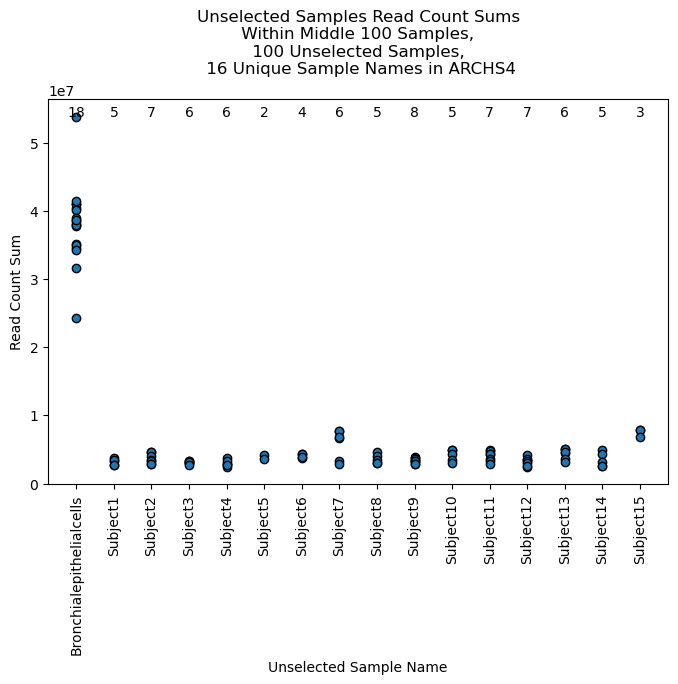

CPU times: user 357 ms, sys: 76.8 ms, total: 434 ms
Wall time: 327 ms


In [27]:
%%time
import json
import matplotlib.pyplot as plt

# Zip names to readCounts - UNNEEDED PROB
unselected_dict = zip(unselected_sample_names, unselected_sample_readCounts)
x, y = zip(*unselected_dict)

# Get the count of dots on each x-value
x_count = {x:unselected_sample_names.count(x) for x in set(unselected_sample_names)}

# Create the bar plot
plt.scatter(x, y, edgecolors='black')
plt.xlabel('Unselected Sample Name')
plt.xticks(rotation=90)
plt.gcf().set_size_inches(8, 5)


# Add the count to each x-value
for x, count in x_count.items():
    plt.annotate(count, (x, max(unselected_sample_readCounts) + 10), ha='center')
    
plt.ylabel('Read Count Sum')
plt.title('Unselected Samples Read Count Sums\n Within Middle 100 Samples, \n 100 Unselected Samples, \n 16 Unique Sample Names in ARCHS4\n')
plt.show()